# Control óptimo de EDOs — Clase 3
**Costo final, condiciones en T y existencia**

FCEN–UBA. Bibliografía principal: Lenhart & Workman, *Optimal Control Applied to Biological Models* (2007).

> Convención del curso: problemas de **máximo** y Hamiltoniano $H = L + \lambda f$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, solve_bvp
from scipy.optimize import brentq, minimize
plt.rcParams.update({'figure.figsize': (7, 3.5), 'axes.grid': True, 'grid.alpha': 0.3})

def integral(v, t):
    """Regla del trapecio."""
    return float(np.sum(0.5*(v[1:] + v[:-1])*np.diff(t)))

Como en la Clase 2, resolvemos con `solve_bvp` el problema de valores de frontera del PMP. Lo nuevo de hoy está
**en las condiciones de borde**: la transversalidad cambia según el costo final y las restricciones sobre $x(T)$.
Cuando hay multiplicadores desconocidos ($\beta$, $\nu$) se los pasa a `solve_bvp` como **parámetros** `p`.

## 1. Tumor: $\min x(T)+\int_0^Tu^2$, $\dot x=\alpha x-u$
Transversalidad: $\lambda(T)=\phi'(x(T))=-1$. Exacto: $u^*=\frac12e^{\alpha(T-t)}$.

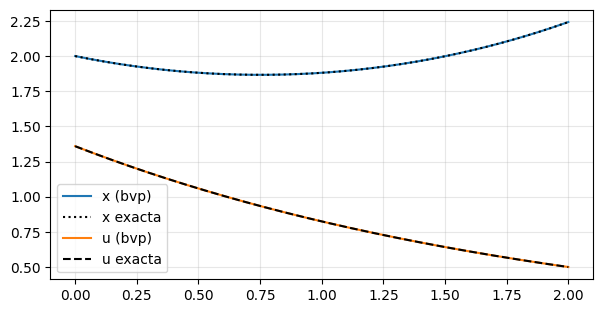

H min/max: -0.8710178043125116 -0.8710178023588409   teoría: -0.8710178037263825


In [2]:
al, T, x0 = 0.5, 2.0, 2.0
sistema = lambda t, y: np.vstack([al*y[0] + y[1]/2, -al*y[1]])     # (x, lambda), u = -lambda/2
bordes = lambda ya, yb: np.array([ya[0] - x0, yb[1] + 1])          # x(0)=x0, lambda(T)=-1
t = np.linspace(0, T, 40)
sol = solve_bvp(sistema, bordes, t, np.zeros((2, t.size)))
tt = np.linspace(0, T, 300); x, lam = sol.sol(tt); u = -lam/2
x_ex = x0*np.exp(al*tt) + np.exp(al*T)*(np.exp(-al*tt) - np.exp(al*tt))/(4*al)
plt.plot(tt, x, label='x (bvp)'); plt.plot(tt, x_ex, 'k:', label='x exacta')
plt.plot(tt, u, label='u (bvp)'); plt.plot(tt, np.exp(al*(T - tt))/2, 'k--', label='u exacta')
plt.legend(); plt.show()
H = -u**2 + lam*(al*x - u)
print('H min/max:', H.min(), H.max(), '  teoría:', np.exp(2*al*T)/4 - al*x0*np.exp(al*T))

## 2. Bacterias: $\max Cx(1)-\int_0^1u^2$, $\dot x=rx+Aux-Bu^2e^{-x}$
$\lambda(1)=C$, $u^*=\frac{\lambda Ax}{2(1+\lambda Be^{-x})}$. No se resuelve a mano, pero sí con `solve_bvp`.

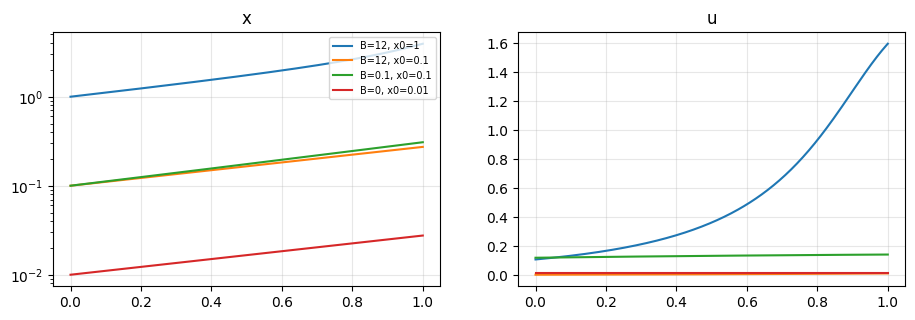

In [3]:
def bacterias(r, A, B, C, x0, T=1.0):
    def F(t, y):
        x, l = y
        u = l*A*x/(2*(1 + l*B*np.exp(-x)))
        return np.vstack([r*x + A*u*x - B*u**2*np.exp(-x), -l*(r + A*u + B*u**2*np.exp(-x))])
    tb = np.linspace(0, T, 50)
    s = solve_bvp(F, lambda ya, yb: np.array([ya[0] - x0, yb[1] - C]), tb,
                  np.vstack([np.full(50, x0), np.full(50, C)]), tol=1e-8)
    tt = np.linspace(0, T, 300); x, l = s.sol(tt)
    return tt, x, l, l*A*x/(2*(1 + l*B*np.exp(-x)))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for (r, A, B, C, x0) in [(1, 1, 12, 1, 1), (1, 1, 12, 1, 0.1), (1, 1, 0.1, 1, 0.1), (1, 1, 0, 1, 0.01)]:
    tt, x, l, u = bacterias(r, A, B, C, x0)
    ax[0].plot(tt, x, label=f'B={B}, x0={x0}'); ax[1].plot(tt, u)
ax[0].set_yscale('log'); ax[0].legend(fontsize=7); ax[0].set_title('x'); ax[1].set_title('u'); plt.show()

**¿Mangasarian?** En $u=0$: $H_{xx}H_{uu}-H_{xu}^2=-\lambda^2A^2<0$, así que $H$ no es cóncava en $(x,u)$.
Lo verificamos numéricamente en algunos puntos $(x,0)$ a lo largo de la solución.

In [4]:
r, A, B = 1, 1, 12
tt, x, l, u = bacterias(r, A, B, 1, 1)
for k in [0, 150, 299]:
    lam_k, xk, uu = l[k], x[k], 0.0
    Hxx = -lam_k*B*uu**2*np.exp(-xk); Huu = -2 - 2*lam_k*B*np.exp(-xk); Hxu = lam_k*(A + 2*B*uu*np.exp(-xk))
    print(f't={tt[k]:.2f}: det del Hessiano en u=0 = {Hxx*Huu - Hxu**2:.4f}  (negativo: no cóncava)')

t=0.00: det del Hessiano en u=0 = -45.0305  (negativo: no cóncava)
t=0.50: det del Hessiano en u=0 = -11.7529  (negativo: no cóncava)
t=1.00: det del Hessiano en u=0 = -1.0000  (negativo: no cóncava)


## 3. Mínima energía con estado final fijo
$\min\int_0^Tu^2$, $\dot x=ax+u$, $x(0)=x^0$, $x(T)=0$. Ahora las dos condiciones de borde son sobre $x$
y **$\lambda(T)$ queda libre**: `solve_bvp` la determina sola.

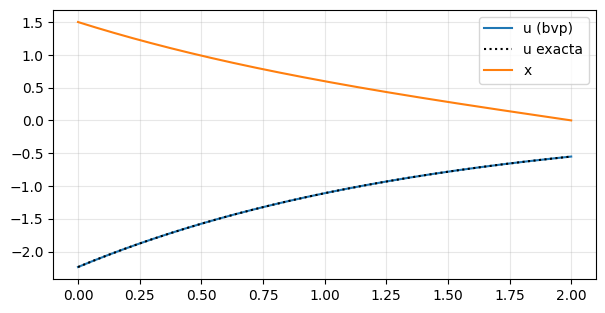

lambda(T) que encontró solve_bvp: -1.1027665532337716   (no es 0: no hay transversalidad)


In [5]:
a, T3, x03 = 0.7, 2.0, 1.5
sist3 = lambda t, y: np.vstack([a*y[0] + y[1]/2, -a*y[1]])          # u = lambda/2
bordes3 = lambda ya, yb: np.array([ya[0] - x03, yb[0] - 0.0])      # x(0)=x0, x(T)=0
t3 = np.linspace(0, T3, 50)
s3 = solve_bvp(sist3, bordes3, t3, np.zeros((2, t3.size)))
tt3 = np.linspace(0, T3, 300); x3, l3 = s3.sol(tt3)
u_ex = -2*a*x03/(1 - np.exp(-2*a*T3))*np.exp(-a*tt3)
plt.plot(tt3, l3/2, label='u (bvp)'); plt.plot(tt3, u_ex, 'k:', label='u exacta'); plt.plot(tt3, x3, label='x')
plt.legend(); plt.show()
print('lambda(T) que encontró solve_bvp:', s3.sol(T3)[1], '  (no es 0: no hay transversalidad)')

## 4. Transversalidad geométrica: llegar a la recta $x_1+x_2=1$
$\min\int_0^1\frac12|u|^2$, $\dot x=u\in\mathbb R^2$, $x(0)=0$. Condiciones en $t=1$: llegar ($x_1+x_2=1$) y
transversalidad ($\lambda\perp S$, es decir $\lambda_1(1)=\lambda_2(1)$). Se espera $x(1)=(\frac12,\frac12)$.

x(1) = [0.5 0.5]   lambda = [0.5 0.5]


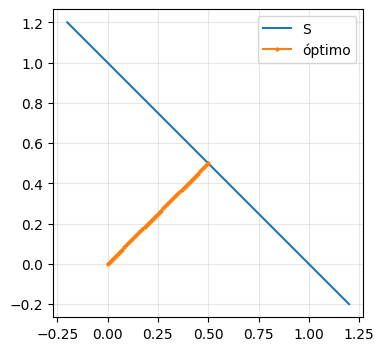

In [6]:
sist4 = lambda t, y: np.vstack([y[2], y[3], 0*y[2], 0*y[3]])       # (x1,x2,l1,l2), u = lambda
bordes4 = lambda ya, yb: np.array([ya[0], ya[1], yb[0] + yb[1] - 1, yb[2] - yb[3]])
t4 = np.linspace(0, 1, 20)
s4 = solve_bvp(sist4, bordes4, t4, np.zeros((4, t4.size)))
print('x(1) =', s4.sol(1)[:2], '  lambda =', s4.sol(1)[2:])
th = np.linspace(-0.2, 1.2, 2)
plt.figure(figsize=(4, 4)); plt.plot(th, 1 - th, label='S'); xx = s4.sol(np.linspace(0, 1, 50))
plt.plot(xx[0], xx[1], 'o-', ms=2, label='óptimo'); plt.axis('equal'); plt.legend(); plt.show()

## 5. Tumor con objetivo $x(T)\le M$: el multiplicador $\beta$
$\min\int_0^Tu^2$, $\dot x=ax-u$. Si la restricción es activa, $\lambda(T)=-\beta$ con $\beta$ **desconocido** y
$x(T)=M$: se lo damos a `solve_bvp` como parámetro. Comparamos con la fórmula y con el tiro (`brentq`).

In [7]:
a5, T5, x05 = 0.5, 2.0, 1.0
def beta_bvp(M):
    F = lambda t, y, p: np.vstack([a5*y[0] + y[1]/2, -a5*y[1]])          # u = -lambda/2
    bc = lambda ya, yb, p: np.array([ya[0] - x05, yb[0] - M, yb[1] + p[0]])  # x(0), x(T)=M, lambda(T)=-beta
    t5 = np.linspace(0, T5, 40)
    s = solve_bvp(F, bc, t5, np.zeros((2, t5.size)), p=[0.1])
    return s.p[0]
def beta_tiro(M):
    xT = lambda b: solve_ivp(lambda t, x: a5*x - b/2*np.exp(a5*(T5 - t)), [0, T5], [x05], rtol=1e-10).y[0, -1]
    return 0.0 if xT(0) <= M else brentq(lambda b: xT(b) - M, 0, 50)
for M in [2.5, 2.0, 1.5, 1.0]:
    formula = max(0, 4*a5*(x05*np.exp(a5*T5) - M)/(np.exp(2*a5*T5) - 1))
    print(f'M={M}: beta bvp={beta_bvp(M):.6f}  tiro={beta_tiro(M):.6f}  fórmula={formula:.6f}')
costo = lambda M: 2*a5*max(0, x05*np.exp(a5*T5) - M)**2/(np.exp(2*a5*T5) - 1)
h = 1e-4
print('d(costo)/dM en M=1.5:', (costo(1.5 + h) - costo(1.5 - h))/(2*h), '  -beta =', -beta_tiro(1.5))

M=2.5: beta bvp=0.068330  tiro=0.068330  fórmula=0.068330
M=2.0: beta bvp=0.224848  tiro=0.224848  fórmula=0.224848
M=1.5: beta bvp=0.381365  tiro=0.381365  fórmula=0.381365
M=1.0: beta bvp=0.537883  tiro=0.537883  fórmula=0.537883
d(costo)/dM en M=1.5: -0.38136519999038   -beta = -0.381365263283279


## 6. Chattering: $\min\int_0^1x^2+(u^2-1)^2$, $\dot x=u$, $x(0)=0$, $u\in\mathbb R$
Con $u_k=\pm1$ alternando cada $1/(2k)$, $J(u_k)=\frac1{12k^2}\to0$, pero ningún control da $J=0$.

In [8]:
t6 = np.linspace(0, 1, 200001)
for k in [1, 2, 4, 8, 16, 32]:
    u = np.where(np.floor(2*k*t6) % 2 == 0, 1.0, -1.0)
    x = np.concatenate([[0], np.cumsum(0.5*(u[1:] + u[:-1])*np.diff(t6))])
    J = integral(x**2 + (u**2 - 1)**2, t6)
    print(f'k={k:3d}  J(u_k)={J:.3e}   1/(12k^2)={1/(12*k**2):.3e}')
print('u = 0:', integral(np.ones_like(t6), t6), ' (el promedio de los pozos no sirve: cuesta 1)')

k=  1  J(u_k)=8.333e-02   1/(12k^2)=8.333e-02
k=  2  J(u_k)=2.083e-02   1/(12k^2)=2.083e-02
k=  4  J(u_k)=5.208e-03   1/(12k^2)=5.208e-03
k=  8  J(u_k)=1.302e-03   1/(12k^2)=1.302e-03
k= 16  J(u_k)=3.254e-04   1/(12k^2)=3.255e-04
k= 32  J(u_k)=8.134e-05   1/(12k^2)=8.138e-05
u = 0: 1.0  (el promedio de los pozos no sirve: cuesta 1)


## 7. Ejercicios nuevos
**Ejercicio 6 (producción con tope):** $\max px(T)-\frac12\int u^2$, $\dot x=u$, $x(0)=0$, $x(T)\le M$.
A mano: inactiva si $pT\le M$ ($u^*=p$); si no, $u^*=M/T$ y $\beta=p-M/T$. Chequeo del precio sombra:

In [9]:
p6, T6 = 1.0, 2.0
valor = lambda M: p6*min(M, p6*T6) - 0.5*(min(M, p6*T6)/T6)**2*T6    # x(T)=min(M,pT), u constante
for M in [3.0, 1.5, 1.0]:
    beta = max(0, p6 - M/T6); h = 1e-5
    print(f'M={M}: d(valor)/dM = {(valor(M + h) - valor(M - h))/(2*h):.5f}   beta = {beta:.5f}')

M=3.0: d(valor)/dM = 0.00000   beta = 0.00000
M=1.5: d(valor)/dM = 0.25000   beta = 0.25000
M=1.0: d(valor)/dM = 0.50000   beta = 0.50000


**Ejercicio 7 (carro, estado final mixto):** $x_1(1)=1$ fijo, $x_2(1)$ libre $\Rightarrow$ $\lambda_2(1)=0$, $\lambda_1(1)$ libre.

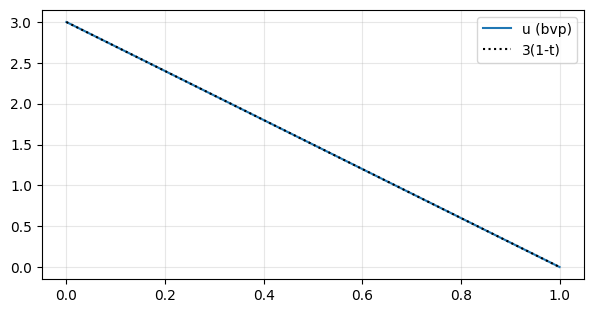

x2(1) = 1.4999999999999998 (teoría 3/2)  | energía = 1.500018938915682 (fijo (1,0): 6)


In [10]:
sist7 = lambda t, y: np.vstack([y[1], y[3], 0*y[2], -y[2]])         # (x1,x2,l1,l2), u = l2
bordes7 = lambda ya, yb: np.array([ya[0], ya[1], yb[0] - 1, yb[3]])   # x(0)=0, x1(1)=1, lambda2(1)=0
t7 = np.linspace(0, 1, 30)
s7 = solve_bvp(sist7, bordes7, t7, np.zeros((4, t7.size)))
tt7 = np.linspace(0, 1, 200); y7 = s7.sol(tt7)
plt.plot(tt7, y7[3], label='u (bvp)'); plt.plot(tt7, 3*(1 - tt7), 'k:', label='3(1-t)'); plt.legend(); plt.show()
print('x2(1) =', s7.sol(1)[1], '(teoría 3/2)  | energía =', 0.5*integral(y7[3]**2, tt7), '(fijo (1,0): 6)')

**Ejercicio 8 (circunferencia):** $x(0)=(2,0)$, $|x(1)|=1$. Transversalidad: $\lambda(1)=2\nu\,x(1)$, con $\nu$
parámetro. Según la semilla, `solve_bvp` encuentra **uno u otro** candidato: el PMP no elige.

In [11]:
def circ(semilla_x1, nu0):
    F = lambda t, y, p: np.vstack([y[2], y[3], 0*y[2], 0*y[3]])
    bc = lambda ya, yb, p: np.array([ya[0] - 2, ya[1], yb[0]**2 + yb[1]**2 - 1,
                                     yb[2] - 2*p[0]*yb[0], yb[3] - 2*p[0]*yb[1]])
    t8 = np.linspace(0, 1, 20)
    y0 = np.vstack([np.linspace(2, semilla_x1, 20), np.zeros(20), np.full(20, semilla_x1 - 2), np.zeros(20)])
    s = solve_bvp(F, bc, t8, y0, p=[nu0])
    lam = s.sol(1)[2:]
    return s.sol(1)[:2], s.p[0], 0.5*np.sum(lam**2)
for sem, nu0 in [(1.0, -0.5), (-1.0, 1.5)]:
    xf, nu, J = circ(sem, nu0)
    print(f'x(1) = {np.round(xf, 4)}, nu = {nu:.4f}, costo = {J:.4f}')

x(1) = [1. 0.], nu = -0.5000, costo = 0.5000
x(1) = [-1.  0.], nu = 1.5000, costo = 4.5000


**Ejercicio 9 (bacterias con meta $x(1)\ge K$, sin premio final):** $\lambda(1)=\beta\ge0$ desconocido.

In [12]:
def bact_meta(K, r=1.0, A=1.0, B=1.0, x0=1.0):
    def F(t, y, p):
        x, l = y; u = l*A*x/(2*(1 + l*B*np.exp(-x)))
        return np.vstack([r*x + A*u*x - B*u**2*np.exp(-x), -l*(r + A*u + B*u**2*np.exp(-x))])
    bc = lambda ya, yb, p: np.array([ya[0] - x0, yb[0] - K, yb[1] - p[0]])
    t9 = np.linspace(0, 1, 50)
    s = solve_bvp(F, bc, t9, np.vstack([np.linspace(x0, K, 50), np.full(50, 0.5)]), p=[0.5], tol=1e-9)
    tt = np.linspace(0, 1, 2001); x, l = s.sol(tt); u = l*A*x/(2*(1 + l*B*np.exp(-x)))
    return integral(u**2, tt), s.p[0]
print('Sin químico: x(1) = e =', np.e, '-> la meta es inactiva si K <= e')
c4, b4 = bact_meta(4.0); c4h, _ = bact_meta(4.01)
print(f'K=4: beta = {b4:.5f}   d(costo)/dK ≈ {(c4h - c4)/0.01:.5f}')

Sin químico: x(1) = e = 2.718281828459045 -> la meta es inactiva si K <= e


K=4: beta = 0.21649   d(costo)/dK ≈ 0.21697


## Para explorar
1. En la sección 5, graficar $\beta$ en función de $M$: ¿dónde se vuelve $0$?
2. En el Ejercicio 8, cambiar el punto inicial a $(0.5,0)$ (adentro del círculo). ¿Qué candidatos aparecen?
3. En el Ejercicio 9, graficar el costo óptimo en función de $K\in[e,6]$ y su pendiente.